In [3]:
import numpy as np
import pandas as pd

# Fixer la graine aléatoire pour que les données soient les mêmes à chaque exécution
np.random.seed(42)

# Nombre de patients (150, ce qui respecte la règle < 200 de l'énoncé)
n_patients = 150

# 1. Génération des variables QUALITATIVES (Sexe et Fumeur)
sexe = np.random.choice(["F", "M"], size=n_patients, p=[0.51, 0.49])
fumeur = np.random.choice(["Oui", "Non"], size=n_patients, p=[0.25, 0.75])

# 2. Génération des variables QUANTITATIVES (au moins 5 requises)
age = np.random.normal(loc=55, scale=12, size=n_patients).astype(int)
imc = np.round(np.random.normal(loc=27.2, scale=4.5, size=n_patients), 1)
pas = np.random.normal(loc=132, scale=15, size=n_patients).astype(int)
cholesterol = np.round(
    np.random.normal(loc=2.10, scale=0.40, size=n_patients), 2
)
glycemie = np.round(np.random.normal(loc=1.05, scale=0.25, size=n_patients), 2)

# Création du tableau de données (DataFrame)
df_medical = pd.DataFrame(
    {
        "Patient_ID": [f"P_{i:03d}" for i in range(1, n_patients + 1)],
        "Sexe": sexe,  # Qualitative 1
        "Fumeur": fumeur,  # Qualitative 2
        "Age": age,  # Quantitative 1
        "IMC": imc,  # Quantitative 2
        "PAS": pas,  # Quantitative 3 (Pression artérielle)
        "Cholesterol": cholesterol,  # Quantitative 4
        "Glycemie": glycemie,  # Quantitative 5
    }
)

# Affichage des 5 premières lignes dans le Notebook
display(df_medical.head())

# Sauvegarde automatique en fichier Excel dans ton dossier
df_medical.to_csv("Patients.csv", index=False)
print("\nSuccès ! Le fichier 'Patients.csv' a été créé.")

,Patient_ID,Sexe,Fumeur,Age,IMC,PAS,Cholesterol,Glycemie
0,P_001,F,Non,55,17.6,131,1.89,0.80
1,P_002,M,Oui,47,24.8,113,2.30,0.86
2,P_003,M,Oui,80,23.8,122,1.61,1.04
3,P_004,M,Non,62,27.9,132,2.39,1.11
4,P_005,F,Non,30,28.7,119,2.00,1.44



Succès ! Le fichier 'Patients.csv' a été créé.


In [4]:
# Affiche le nombre total de lignes et de colonnes (150 lignes, 8 colonnes)
print("Dimensions du tableau (Lignes, Colonnes) :", df_medical.shape)

Dimensions du tableau (Lignes, Colonnes) : (150, 8)


In [5]:
# 1. Statistiques descriptives pour les variables QUANTITATIVES (Age, IMC, PAS, etc.)
print("--- STATISTIQUES QUANTITATIVES ---")
print(df_medical.describe().round(2))

# 2. Statistiques descriptives pour les variables QUALITATIVES (Sexe et Fumeur)
print("\n--- STATISTIQUES QUALITATIVES ---")
print("\nFréquences - Sexe :")
print(df_medical["Sexe"].value_counts(normalize=True) * 100)

print("\nFréquences - Fumeur :")
print(df_medical["Fumeur"].value_counts(normalize=True) * 100)

--- STATISTIQUES QUANTITATIVES ---
          Age     IMC     PAS  Cholesterol  Glycemie
count  150.00  150.00  150.00       150.00    150.00
mean    55.24   26.80  131.45         2.11      1.09
std     11.16    4.71   15.68         0.37      0.24
min     16.00   16.80   91.00         1.27      0.44
25%     47.00   23.30  123.00         1.87      0.91
50%     55.00   26.75  131.00         2.11      1.10
75%     62.00   30.00  142.00         2.35      1.23
max     81.00   41.10  170.00         3.15      1.68

--- STATISTIQUES QUALITATIVES ---

Fréquences - Sexe :
Sexe
F    54.666667
M    45.333333
Name: proportion, dtype: float64

Fréquences - Fumeur :
Fumeur
Non    74.666667
Oui    25.333333
Name: proportion, dtype: float64


In [2]:
!pip install openpyxl

You should consider upgrading via the 'C:\PySchool\3.10-32-bit\python.exe -m pip install --upgrade pip' command.


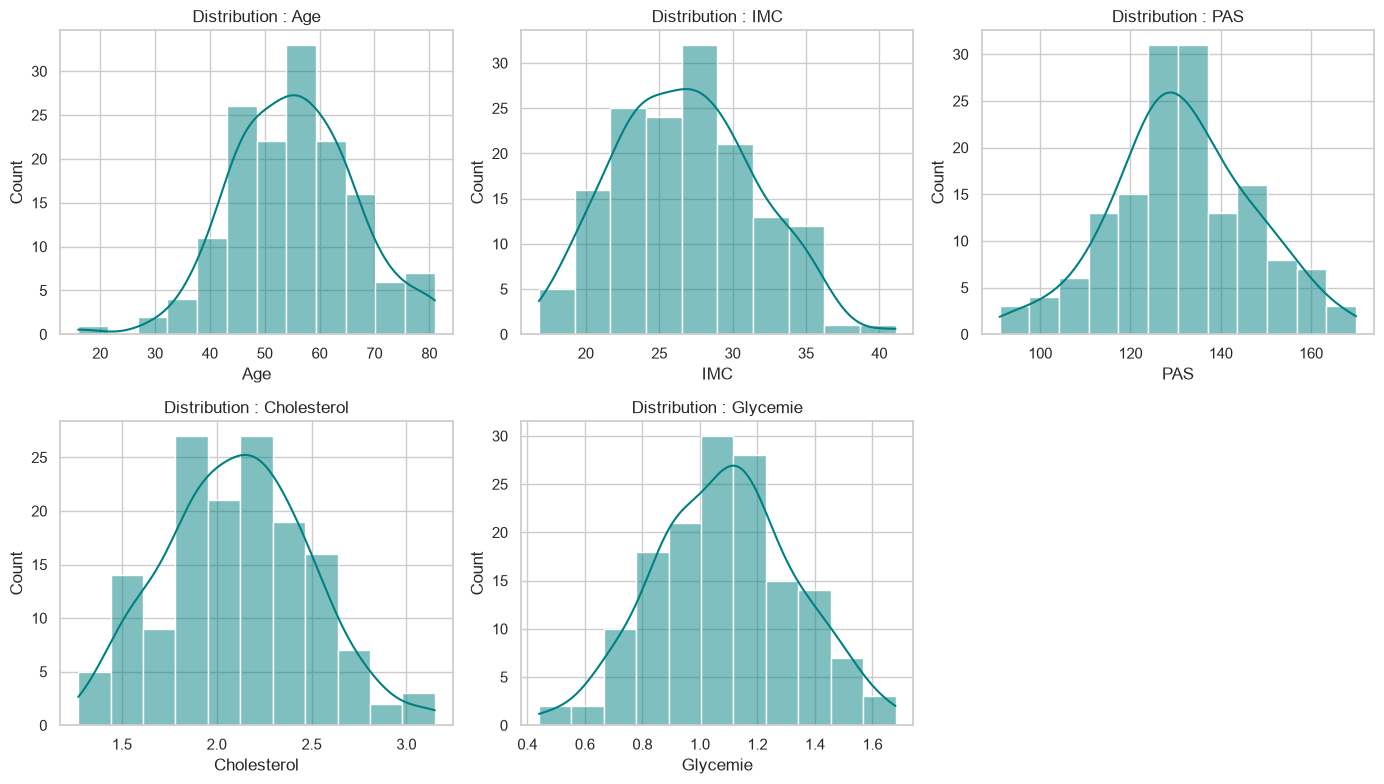

In [13]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style
sns.set_theme(style="whitegrid")

# 1. Histogrammes pour les variables quantitatives
plt.figure(figsize=(14, 8))
quant_vars = ["Age", "IMC", "PAS", "Cholesterol", "Glycemie"]

for i, col in enumerate(quant_vars, 1):
  plt.subplot(2, 3, i)
  sns.histplot(df_medical[col], kde=True, color="teal")
  plt.title(f"Distribution : {col}")

plt.tight_layout()
plt.show()

In [7]:
!pip install seaborn matplotlib

     -------------------------------------- 294.9/294.9 KB 1.8 MB/s eta 0:00:00


You should consider upgrading via the 'C:\PySchool\3.10-32-bit\python.exe -m pip install --upgrade pip' command.


In [12]:
import sys

!{sys.executable} -m pip install seaborn

   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   ---------------------------------------- 0.0/294.9 kB ? eta -:--:--
   - -------------------------------------- 10.2/294.9 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/294.9 kB 259.2 kB/s eta 0:00:02
   ----- --------------------------------- 41.0/294.9 kB 279.3 kB/s eta 0:00:01
   --------- ----------------------------- 71.7/294.9 kB 435.7 kB/s eta 0:00:01
   --------------- ---------------------- 122.9/294.9 kB 654.9 kB/s eta 0:00:01
   ------------------------------ ------- 235.5/294.9 kB 958.6 kB/s eta 0:00:01
   -------------------------------------- - 286.7/294.9 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 294.9/294.9 kB 1.0 MB/s eta 0:00:00



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [14]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Sélection des variables quantitatives
X = df_medical[["Age", "IMC", "PAS", "Cholesterol", "Glycemie"]]

# 2. Centrer-réduire les données (indispensable pour l'ACP)
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# 3. Application de l'ACP
pca = PCA()
coords_pca = pca.fit_transform(X_scaled)

# 4. Affichage des pourcentages de variance expliquée
variance_ratio = pca.explained_variance_ratio_ * 100

print("--- ANALYSE EN COMPOSANTES PRINCIPALES (ACP) ---")
for i, var in enumerate(variance_ratio, 1):
  print(f"Axe {i} : {var:.2f}% de la variance")

print(
    f"\nVariance cumulée (Axe 1 + Axe 2) :"
    f" {sum(variance_ratio[:2]):.2f}%"
)

--- ANALYSE EN COMPOSANTES PRINCIPALES (ACP) ---
Axe 1 : 24.93% de la variance
Axe 2 : 22.03% de la variance
Axe 3 : 20.33% de la variance
Axe 4 : 18.43% de la variance
Axe 5 : 14.28% de la variance

Variance cumulée (Axe 1 + Axe 2) : 46.96%


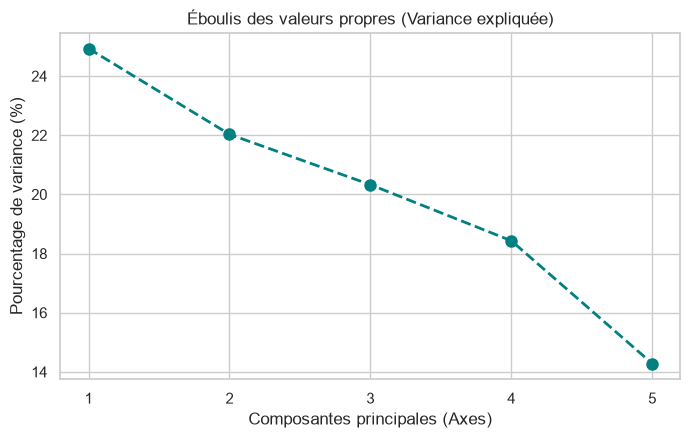

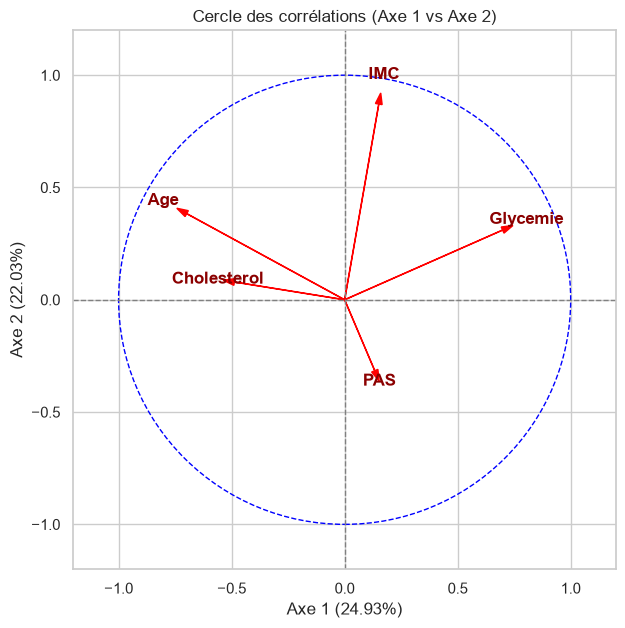

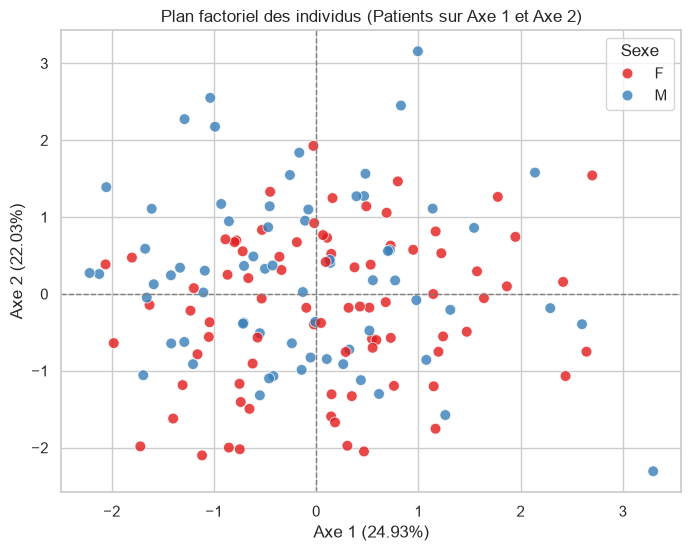

In [15]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# 1. Sélection et centrage-réduction des données quantitatives
X = df_medical[["Age", "IMC", "PAS", "Cholesterol", "Glycemie"]]
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Application de l'ACP
pca = PCA()
coords_pca = pca.fit_transform(X_scaled)
variance_ratio = pca.explained_variance_ratio_ * 100

# ==========================================
# GRAPHIQUE 1 : L'éboulis des valeurs propres
# ==========================================
plt.figure(figsize=(8, 4.5))
plt.plot(
    range(1, len(variance_ratio) + 1),
    variance_ratio,
    marker="o",
    linestyle="--",
    color="teal",
    linewidth=2,
    markersize=8,
)
plt.title("Éboulis des valeurs propres (Variance expliquée)")
plt.xlabel("Composantes principales (Axes)")
plt.ylabel("Pourcentage de variance (%)")
plt.xticks(range(1, len(variance_ratio) + 1))
plt.grid(True)
plt.show()

# ==========================================
# GRAPHIQUE 2 : Le cercle des corrélations
# ==========================================
# Calcul des coordonnées des variables (loadings)
loadings = pca.components_.T * np.sqrt(pca.explained_variance_)

plt.figure(figsize=(7, 7))
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)

# Tracé du cercle unité (cercle de rayon 1)
circle = plt.Circle((0, 0), 1, color="blue", fill=False, linestyle="--")
plt.gca().add_artist(circle)

# Tracé des vecteurs pour chaque variable
for i, var in enumerate(X.columns):
  plt.arrow(
      0,
      0,
      loadings[i, 0],
      loadings[i, 1],
      head_width=0.03,
      head_length=0.05,
      fc="red",
      ec="red",
  )
  plt.text(
      loadings[i, 0] * 1.15,
      loadings[i, 1] * 1.15,
      var,
      color="darkred",
      ha="center",
      va="center",
      weight="bold",
  )

plt.xlim(-1.2, 1.2)
plt.ylim(-1.2, 1.2)
plt.title("Cercle des corrélations (Axe 1 vs Axe 2)")
plt.xlabel(f"Axe 1 ({variance_ratio[0]:.2f}%)")
plt.ylabel(f"Axe 2 ({variance_ratio[1]:.2f}%)")
plt.grid(True)
plt.show()

# ==========================================
# GRAPHIQUE 3 : Plan factoriel des individus
# ==========================================
plt.figure(figsize=(8, 6))
sns.scatterplot(
    x=coords_pca[:, 0],
    y=coords_pca[:, 1],
    hue=df_medical["Sexe"],
    palette="Set1",
    alpha=0.8,
    s=60,
)
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.title("Plan factoriel des individus (Patients sur Axe 1 et Axe 2)")
plt.xlabel(f"Axe 1 ({variance_ratio[0]:.2f}%)")
plt.ylabel(f"Axe 2 ({variance_ratio[1]:.2f}%)")
plt.legend(title="Sexe")
plt.grid(True)
plt.show()

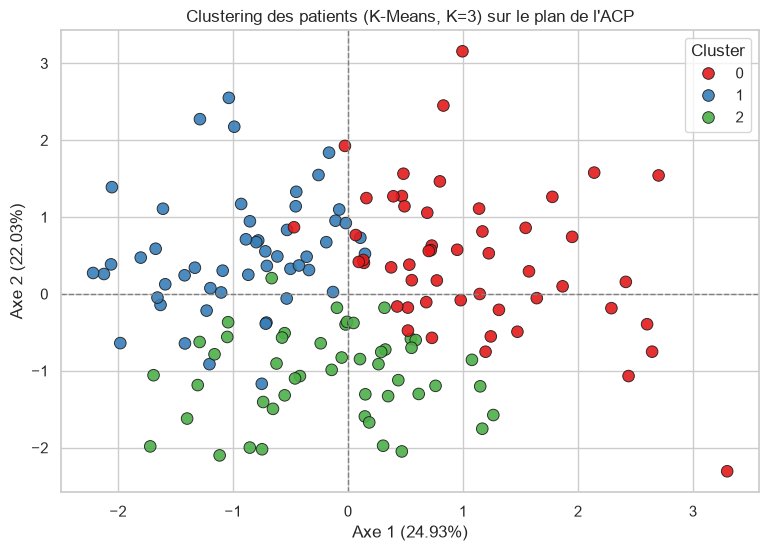

--- PROFIL MOYEN DE CHAQUE CLUSTER ---
           Age    IMC     PAS  Cholesterol  Glycemie
Cluster                                             
0        49.00  29.15  129.08         1.95      1.28
1        64.39  28.26  131.92         2.37      1.03
2        52.15  22.75  133.46         2.00      0.95


In [16]:
from sklearn.cluster import KMeans

# 1. Application de l'algorithme K-Means (on choisit 3 groupes / clusters)
kmeans = KMeans(n_clusters=3, random_state=42, n_init=10)
clusters = kmeans.fit_predict(X_scaled)

# 2. Ajouter le numéro du cluster dans notre tableau de données
df_medical["Cluster"] = clusters

# 3. Visualisation des clusters sur le plan factoriel de l'ACP
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=coords_pca[:, 0],
    y=coords_pca[:, 1],
    hue=df_medical["Cluster"],
    palette="Set1",
    s=70,
    alpha=0.9,
    edgecolor="k",
)
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.title("Clustering des patients (K-Means, K=3) sur le plan de l'ACP")
plt.xlabel(f"Axe 1 ({variance_ratio[0]:.2f}%)")
plt.ylabel(f"Axe 2 ({variance_ratio[1]:.2f}%)")
plt.legend(title="Cluster")
plt.grid(True)
plt.show()

# 4. Calculer les moyennes des variables pour chaque cluster (pour interpréter les groupes)
print("--- PROFIL MOYEN DE CHAQUE CLUSTER ---")
quant_vars = ["Age", "IMC", "PAS", "Cholesterol", "Glycemie"]
print(df_medical.groupby("Cluster")[quant_vars].mean().round(2))

In [17]:
import sys

!{sys.executable} -m pip install prince

   ---------------------------------------- 0.0/207.8 kB ? eta -:--:--
   ------- ------------------------------- 41.0/207.8 kB 653.6 kB/s eta 0:00:01
   --------------------------------- ------ 174.1/207.8 kB 2.1 MB/s eta 0:00:01
   ---------------------------------------- 207.8/207.8 kB 2.1 MB/s eta 0:00:00
   ---------------------------------------- 0.0/797.2 kB ? eta -:--:--
   -------- ------------------------------- 174.1/797.2 kB 5.3 MB/s eta 0:00:01
   ------------------- -------------------- 389.1/797.2 kB 6.1 MB/s eta 0:00:01
   -------------------------------- ------- 645.1/797.2 kB 5.8 MB/s eta 0:00:01
   ---------------------------------------- 797.2/797.2 kB 5.6 MB/s eta 0:00:00
   ---------------------------------------- 0.0/90.6 kB ? eta -:--:--
   ---------------------------------------- 90.6/90.6 kB 5.0 MB/s eta 0:00:00
   ---------------------------------------- 0.0/134.9 kB ? eta -:--:--
   --------------------- ------------------ 71.7/134.9 kB 1.9 MB/s eta 0:00:01



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


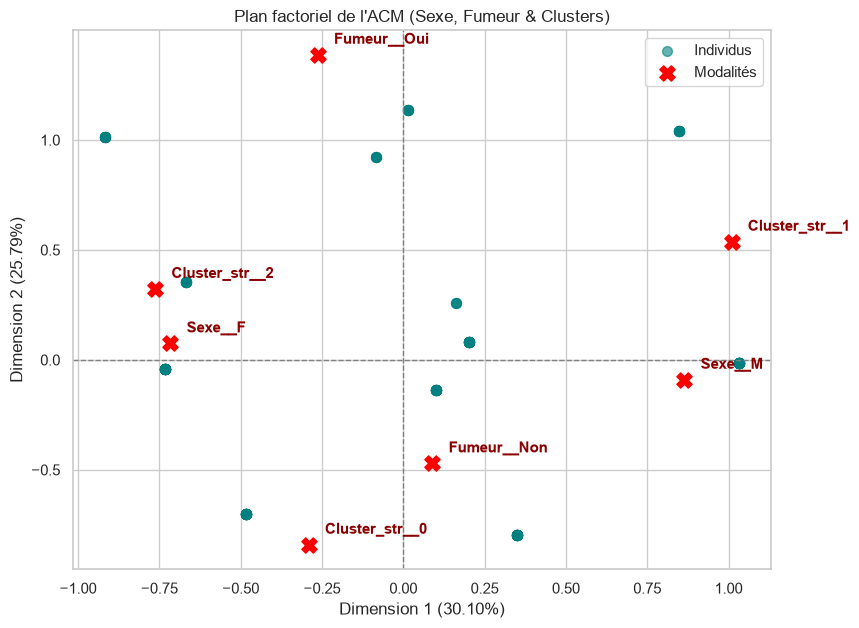

In [24]:
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Récupérer les coordonnées des individus (lignes) et des modalités (colonnes)
row_coords = mca.row_coordinates(X_quali)
col_coords = mca.column_coordinates(X_quali)

# 2. Création de la figure
plt.figure(figsize=(9, 7))

# Tracé des individus (patients)
plt.scatter(
    row_coords.iloc[:, 0],
    row_coords.iloc[:, 1],
    color="teal",
    alpha=0.6,
    label="Individus",
    s=50,
)

# Tracé des modalités (Sexe, Fumeur, Clusters)
plt.scatter(
    col_coords.iloc[:, 0],
    col_coords.iloc[:, 1],
    color="red",
    s=120,
    marker="X",
    label="Modalités",
)

# Ajouter les noms des modalités pour les identifier facilement
for idx, row in col_coords.iterrows():
  plt.text(
      row.iloc[0] + 0.05,
      row.iloc[1] + 0.05,
      str(idx),
      color="darkred",
      weight="bold",
      fontsize=11,
  )

# Mise en page du graphique
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.title("Plan factoriel de l'ACM (Sexe, Fumeur & Clusters)")
plt.xlabel("Dimension 1 (30.10%)")
plt.ylabel("Dimension 2 (25.79%)")
plt.legend()
plt.grid(True)
plt.show()

--- MATRICE DE CORRÉLATION ---
              Age   IMC   PAS  Cholesterol  Glycemie
Age          1.00  0.09 -0.02         0.12     -0.18
IMC          0.09  1.00 -0.05        -0.02      0.13
PAS         -0.02 -0.05  1.00         0.01      0.05
Cholesterol  0.12 -0.02  0.01         1.00     -0.05
Glycemie    -0.18  0.13  0.05        -0.05      1.00

--- RÉSULTATS DU MODÈLE LINÉAIRE ---
                            OLS Regression Results                            
Dep. Variable:                    PAS   R-squared:                       0.002
Model:                            OLS   Adj. R-squared:                 -0.005
Method:                 Least Squares   F-statistic:                    0.3068
Date:                Mon, 09 Nov 2026   Prob (F-statistic):              0.580
Time:                        23:47:47   Log-Likelihood:                -625.00
No. Observations:                 150   AIC:                             1254.
Df Residuals:                     148   BIC:                

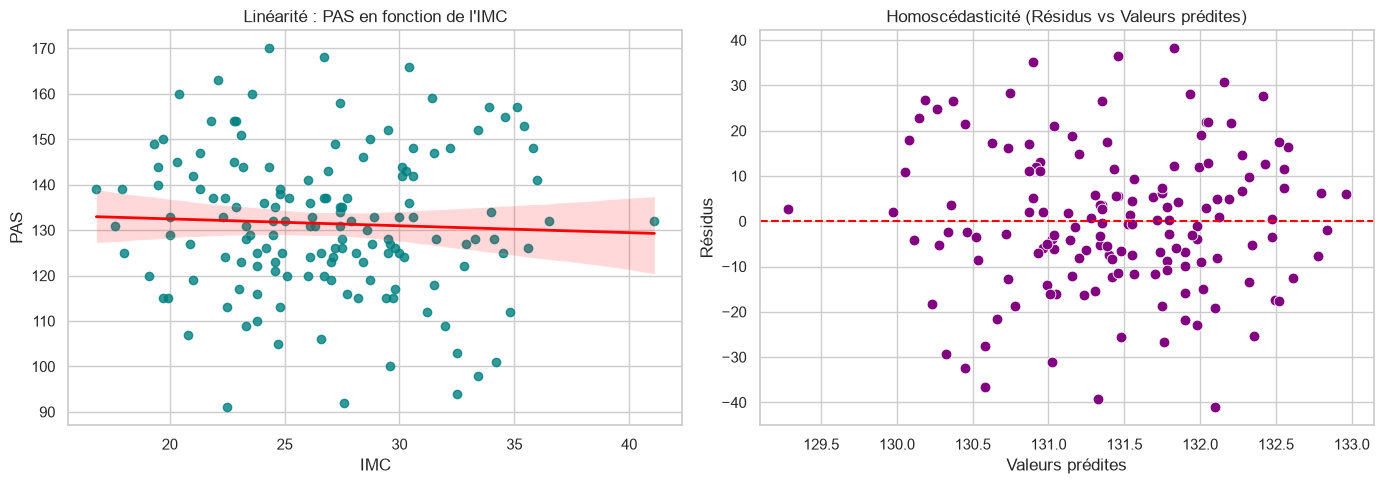

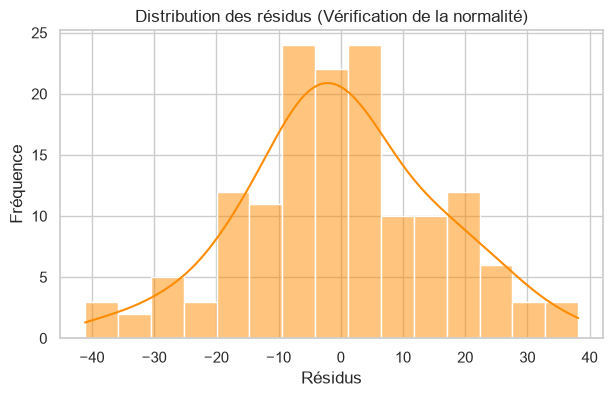

In [27]:
import matplotlib.pyplot as plt
import seaborn as sns
import statsmodels.api as sm
import statsmodels.formula.api as smf

# 1. Aperçu des corrélations linéaires pour choisir les variables à modéliser
quant_vars = ["Age", "IMC", "PAS", "Cholesterol", "Glycemie"]
print("--- MATRICE DE CORRÉLATION ---")
print(df_medical[quant_vars].corr().round(2))

# 2. Ajustement du modèle linéaire simple
# Exemple : Modéliser la Pression Artérielle (PAS) en fonction de l'IMC
# (Tu peux remplacer "PAS ~ IMC" par une autre paire si tu préfères, ex: "Cholesterol ~ Age")
model = smf.ols("PAS ~ IMC", data=df_medical).fit()

print("\n--- RÉSULTATS DU MODÈLE LINÉAIRE ---")
print(model.summary())

# ==========================================
# 3. VÉRIFICATION DES HYPOTHÈSES DU MODÈLE
# ==========================================
fitted_vals = model.fittedvalues
residuals = model.resid

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Hypothèse 1 : Linéarité (Nuage de points et droite de régression)
sns.regplot(
    x="IMC",
    y="PAS",
    data=df_medical,
    ax=axes[0],
    color="teal",
    line_kws={"color": "red", "linewidth": 2},
)
axes[0].set_title("Linéarité : PAS en fonction de l'IMC")
axes[0].grid(True)

# Hypothèse 2 : Homoscédasticité (Résidus vs Valeurs ajustées)
# La variance des résidus doit être constante (pas d'effet entonnoir)
sns.scatterplot(x=fitted_vals, y=residuals, ax=axes[1], color="purple", s=60)
axes[1].axhline(0, color="red", linestyle="--", linewidth=1.5)
axes[1].set_title("Homoscédasticité (Résidus vs Valeurs prédites)")
axes[1].set_xlabel("Valeurs prédites")
axes[1].set_ylabel("Résidus")
axes[1].grid(True)

plt.tight_layout()
plt.show()

# Hypothèse 3 : Normalité des résidus
plt.figure(figsize=(7, 4))
sns.histplot(residuals, kde=True, color="darkorange", bins=15)
plt.title("Distribution des résidus (Vérification de la normalité)")
plt.xlabel("Résidus")
plt.ylabel("Fréquence")
plt.grid(True)
plt.show()

In [26]:
import sys

!{sys.executable} -m pip install statsmodels

   ---------------------------------------- 0.0/11.4 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.4 MB 660.6 kB/s eta 0:00:18
    --------------------------------------- 0.1/11.4 MB 1.7 MB/s eta 0:00:07
    --------------------------------------- 0.3/11.4 MB 2.3 MB/s eta 0:00:05
   - -------------------------------------- 0.5/11.4 MB 3.3 MB/s eta 0:00:04
   -- ------------------------------------- 0.8/11.4 MB 3.8 MB/s eta 0:00:03
   --- ------------------------------------ 1.0/11.4 MB 3.9 MB/s eta 0:00:03
   ---- ----------------------------------- 1.2/11.4 MB 4.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.4/11.4 MB 4.3 MB/s eta 0:00:03
   ----- ---------------------------------- 1.6/11.4 MB 4.6 MB/s eta 0:00:03
   ------ --------------------------------- 1.8/11.4 MB 4.5 MB/s eta 0:00:03
   ------- -------------------------------- 2.1/11.4 MB 4.7 MB/s eta 0:00:02
   -------- ------------------------------- 2.3/11.4 MB 4.7 MB/s eta 0:00:02
   -


[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


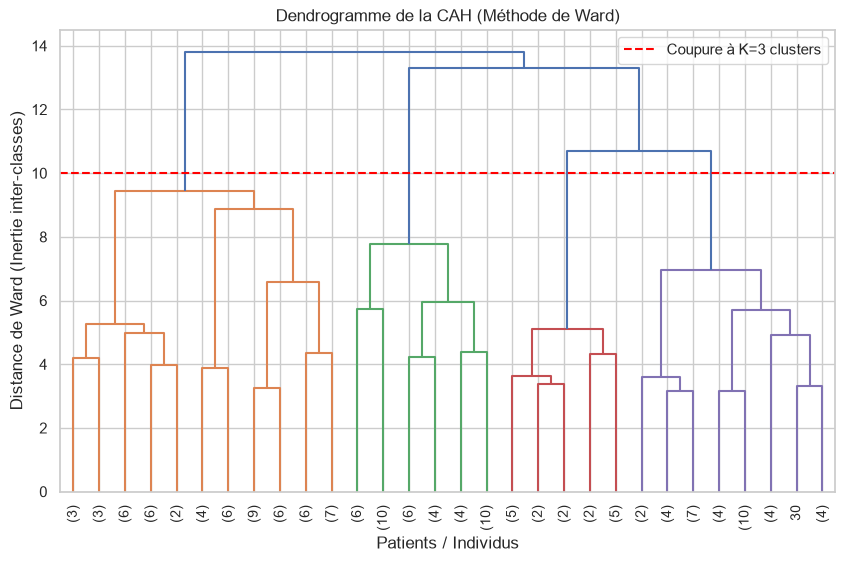

--- MATRICE DE CROISEMENT (K-MEANS vs CAH) ---
CAH       0   1   2
K-Means            
0        12  35   4
1         4  21  26
2        36   2  10

Indice d'Ajustement de Rand (ARI) : 0.261


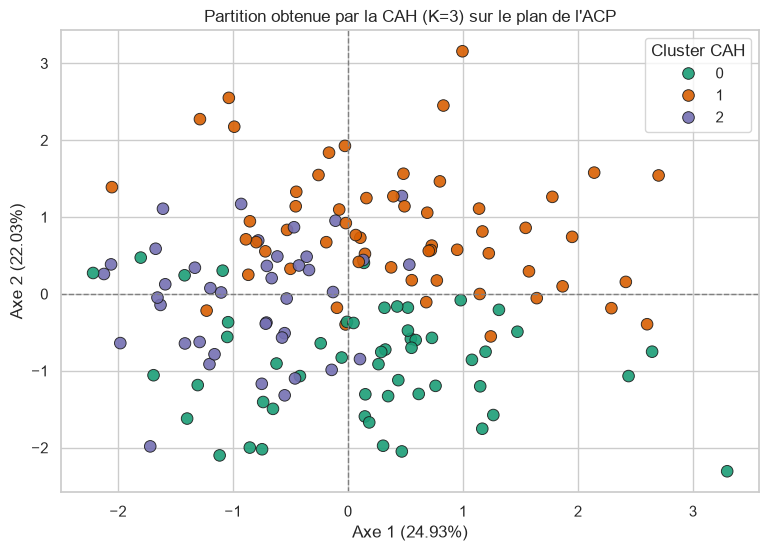

In [28]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from scipy.cluster.hierarchy import dendrogram, linkage
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import adjusted_rand_score, confusion_matrix

# 1. Matrice de liens (Linkage matrix) avec la méthode de Ward sur les données centrées-réduites (X_scaled)
Z = linkage(X_scaled, method="ward")

# 2. Affichage du Dendrogramme
plt.figure(figsize=(10, 6))
plt.title("Dendrogramme de la CAH (Méthode de Ward)")
plt.xlabel("Patients / Individus")
plt.ylabel("Distance de Ward (Inertie inter-classes)")
dendrogram(Z, truncate_mode="lastp", p=30, leaf_rotation=90., leaf_font_size=10.)
plt.axhline(y=10, color="red", linestyle="--", label="Coupure à K=3 clusters")
plt.legend()
plt.grid(True)
plt.show()

# 3. Application de la CAH pour 3 clusters
cah = AgglomerativeClustering(n_clusters=3, metric="euclidean", linkage="ward")
df_medical["Cluster_CAH"] = cah.fit_predict(X_scaled)

# 4. Comparaison entre les partitions K-Means et CAH
conf_matrix = pd.crosstab(
    df_medical["Cluster"],
    df_medical["Cluster_CAH"],
    rownames=["K-Means"],
    colnames=["CAH"],
)
ari_score = adjusted_rand_score(df_medical["Cluster"], df_medical["Cluster_CAH"])

print("--- MATRICE DE CROISEMENT (K-MEANS vs CAH) ---")
print(conf_matrix)
print(f"\nIndice d'Ajustement de Rand (ARI) : {ari_score:.3f}")

# 5. Visualisation de la partition CAH sur le plan factoriel de l'ACP
plt.figure(figsize=(9, 6))
sns.scatterplot(
    x=coords_pca[:, 0],
    y=coords_pca[:, 1],
    hue=df_medical["Cluster_CAH"],
    palette="Dark2",
    s=70,
    alpha=0.9,
    edgecolor="k",
)
plt.axhline(0, color="grey", linestyle="--", linewidth=1)
plt.axvline(0, color="grey", linestyle="--", linewidth=1)
plt.title("Partition obtenue par la CAH (K=3) sur le plan de l'ACP")
plt.xlabel(f"Axe 1 ({variance_ratio[0]:.2f}%)")
plt.ylabel(f"Axe 2 ({variance_ratio[1]:.2f}%)")
plt.legend(title="Cluster CAH")
plt.grid(True)
plt.show()